<a href="https://colab.research.google.com/github/Luiz-FelipeDev/numpy-fudamentals/blob/main/B1_Colab_%2B_Numpy_Essencial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

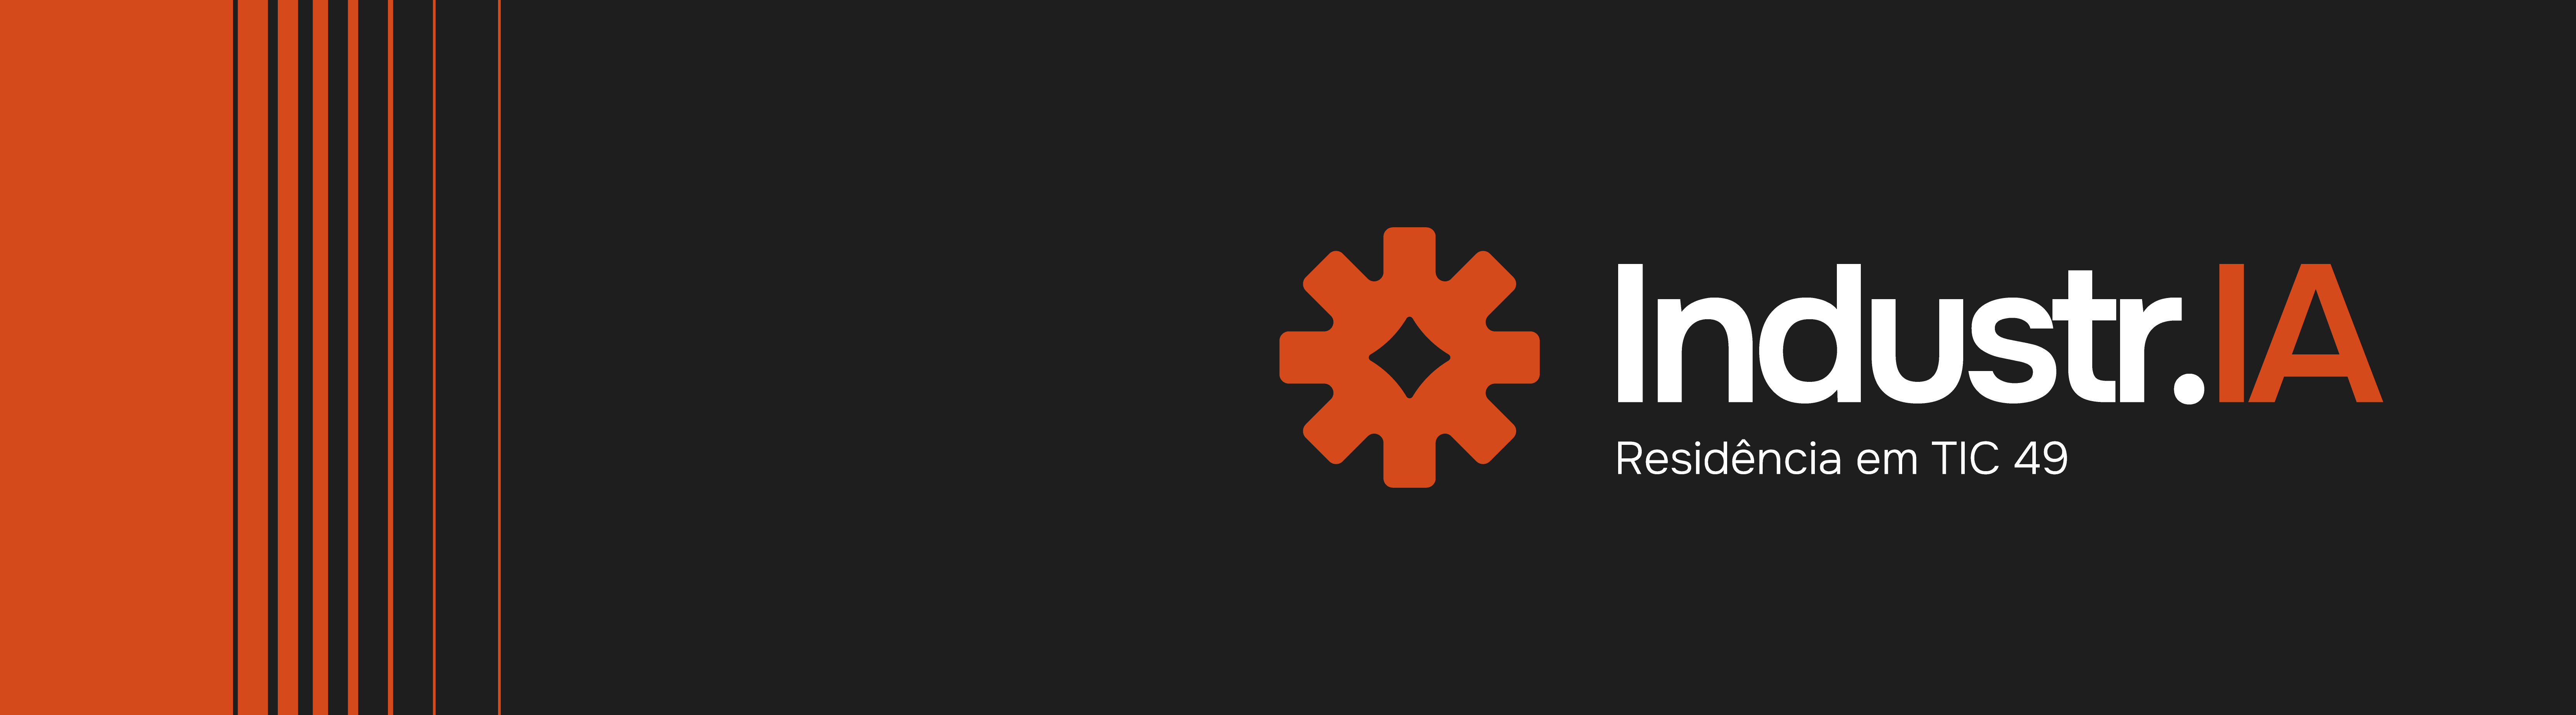

# Introdução à Programação com IA

## 📘 Bloco B1: Colab + NumPy Essencial

---

### 🎯 Visão Geral do Bloco
Este bloco vai ambientar você no ecossistema do Google Colab e consolidar a manipulação eficiente de dados estruturados utilizando a biblioteca **NumPy**. Ao final deste bloco, você será capaz de operar o ambiente de nuvem e aplicar operações vetorizadas de alta performance.

## 📖 Glossário de Termos

Caso tenha alguma dúvida sobre qualquer termo técnico utilizado nesta aula, você pode acessar o nosso material de consulta rápida clicando no link abaixo:

👉 Acessar o Glossário de Termos Técnicos deste Bloco

**Dica: Deixe o glossário aberto em uma aba ao lado para consultar na medida que apareçam as dúvidas.**

## Seção 1: O Ambiente de Execução

O Google Colab é um ambiente de desenvolvimento baseado em Jupyter Notebooks que roda diretamente na nuvem. Ele permite escrever e executar código Python através do navegador, eliminando a necessidade de qualquer configuração local na sua máquina.

🚀 Principais Vantagens:

* Hardware Potente Gratuito: Acesso a GPUs e TPUs de alto desempenho, ideais para processamento de dados e IA.

* Integração com o Ecossistema Google: Conexão nativa com o Google Drive para salvar, organizar e compartilhar projetos industriais e corporativos.

* Ambiente Interativo: O código é estruturado em células, que podem ser executadas individualmente. Além de Python, essas células permitem interagir diretamente com o terminal do sistema operacional subjacente.

In [2]:
# Para executar comandos de terminal diretamente na célula use "!".
# Este comando instala o pacote necessário para essa aula.
!pip install numpy pandas

Como o Google Colab já vem configurado com as principais ferramentas de Ciência de Dados, os pacotes NumPy e Pandas já estão pré-instalados nativamente. Por isso, ao executar o comando de instalação, o terminal exibirá a mensagem Requirement already satisfied (Requisito já atendido).

Caso uma biblioteca não estivesse presente, o gerenciador de pacotes (pip) faria o download automático dela e de todas as suas dependências.

#### ❗ Dependências

**Dependências** são outros pacotes de software necessários para que uma biblioteca funcione corretamente.

O Pandas, por exemplo, não é uma ilha isolada. Ele foi construído sobre o NumPy e depende de outros pacotes para realizar diversas tarefas (datas, fusos horários, etc.).

Diagrama de dependências principais:

```
📦 numpy (não possui dependências)

📦 pandas
├── 📦 python-dateutil
├── 📦 pytz  
├── 📦 tzdata
└── 📦 numpy (o pandas necessita do numpy para operar)
```

### Importando e Explorando Bibliotecas

Após garantir que o pacote está instalado, precisamos importá-lo para o nosso código, definindo um "apelido" (alias) padrão para facilitar a escrita.

No ambiente Colab, também podemos usar o operador ? logo após o nome de qualquer objeto ou função para abrir rapidamente a sua documentação oficial e entender como utilizá-lo.

In [3]:
# Neste bloco, vamos trabalhar primeiramente com o NumPy.
# "np" é um apelido amplamente utilizado para nos referirmos à biblioteca numpy.
import numpy as np

# EXECUTAR ESTA LINHA ABRIRÁ A DOCUMENTAÇÃO NA LATERAL DIREITA DA TELA ->.
# Você pode fechar a janela de ajuda clicando no "X" quando terminar de ler.
np?

## Seção 2: Por que usar Numpy?

No ambiente industrial, lidamos com milhares de sensores gerando dados a cada milissegundo. Será que o Python puro aguenta o tranco com eficiência? Vamos revisar os conceitos e testar a performance.

Imagine um sensor de alta frequência monitorando a temperatura de uma caldeira. Ele gerou uma lista com 1 milhão de leituras em Celsius. Nosso objetivo é converter todas essas leituras para Kelvin:$$K = °C + 273.15$$

Primeiro, vamos gerar nossa massa de dados fictícia usando ```np.random.uniform``` do Numpy.


#### ⚙️  np.random.uniform

Gera valores aleatórios com distribuição uniforme dentro de um intervalo especificado. Nesse tipo de distribuição, todos os valores possuem a mesma probabilidade de serem escolhidos.

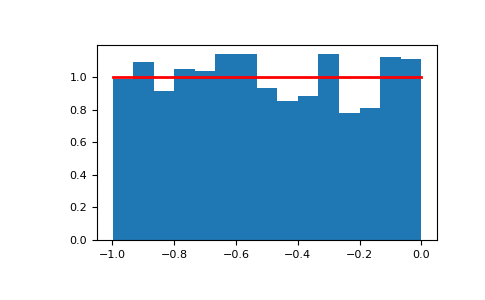

In [4]:
# Gerando 1 milhão de simulações de leituras de temperatura
# Distribuição Uniforme (todos os valores igualmente prováveis)
leituras_celsius_array = np.random.uniform(low=20.0, high=120.0, size=1_000_000)

# Convertendo em uma lista Python
leituras_celsius_lista = leituras_celsius_array.tolist()

### 2.1. Abordagem 1: Python Puro

Aqui revisamos a estrutura clássica. Criamos uma função que recebe a lista e usa uma compreensão de lista para transformar os dados.

In [5]:
# Função tradicional com List Comprehension
def converter_em_kelvin_python_puro(leituras):
    return [t + 273.15 for t in leituras]

# Teste rápido com poucas leituras
print("Amostra das primeiras 4 conversões:")
print(converter_em_kelvin_python_puro(leituras_celsius_lista[:4]))

Amostra das primeiras 4 conversões:
[336.80086586911654, 370.45852060028994, 356.2147189100607, 329.55352661269114]


#### ⚙️  Medindo o tempo

Agora, vamos medir o tempo que o Python leva para processar esse 1 milhão de registros utilizando o comando mágico ```%%timeit```. Esse comando executa o código em ```r``` execuções, cada uma contendo ```n``` loops, para obter uma média precisa do tempo de execução.

In [6]:
# 3 repetições, cada uma com 100 loops
%%timeit -r 3 -n 100
# Medindo a performance do Python Puro
converter_em_kelvin_python_puro(leituras_celsius_lista)

79.2 ms ± 12.8 ms per loop (mean ± std. dev. of 3 runs, 100 loops each)


### 2.2. Abordagem 2: Alta Performance com NumPy (Vetorização)

Agora veja como o ```NumPy``` resolve o mesmo problema. Graças à vetorização, a operação matemática é aplicada a todos os elementos simultaneamente a nível de hardware (em C).

In [7]:
# No NumPy, a função pode ser direta ou simplesmente a operação no array
def converter_em_kelvin_numpy(leituras_array):
    return leituras_array + 273.15

# Teste rápido com a amostra do array
print("Amostra das primeiras 4 conversões com NumPy:")
print(converter_em_kelvin_numpy(leituras_celsius_array[:4]))

Amostra das primeiras 4 conversões com NumPy:
[336.80086587 370.4585206  356.21471891 329.55352661]


Vamos medir o tempo da abordagem NumPy com o mesmo volume de dados:

In [8]:
%%timeit -r 3 -n 100
# Medindo a performance do NumPy
converter_em_kelvin_numpy(leituras_celsius_array)

1.56 ms ± 231 µs per loop (mean ± std. dev. of 3 runs, 100 loops each)


#### ❗ Desempenho

Repare nas unidades de tempo de cada estratégia (geralmente milissegundos ms para o Python puro e microssegundos µs ou nanossegundos ns para o NumPy).

O NumPy costuma ser de 10x a 50x mais rápido que a compreensão de listas para volumes industriais de dados. É por isso que ele é o alicerce da Inteligência Artificial: velocidade e eficiência de memória!

## Seção 3: NumPy - Manipulação de Matrizes

Diferente das listas Python, o ```ndarray``` (```N-dimensional array```)  - matriz N-dimensional - armazena dados de forma contígua em memória e exige tipos homogêneos (todos os dados iguais), sendo até 100 vezes mais rápido para processar milhões de sinais de sensores. Arrays podem ter múltiplas dimensões: 1D (série temporal de um sensor), 2D (matriz de sensores em uma prensa) ou 3D (lote de dias x sensores x horários).

#### ⚙️ np.random.normal

Vamos gerar valores aleatórios seguindo uma distribuição normal (gaussiana), em que os valores tendem a se concentrar em torno de uma média (```loc```, localização). O parâmetro ```scale``` define a dispersão dos valores ao redor dessa média: quanto maior o valor, mais espalhados estarão os dados.

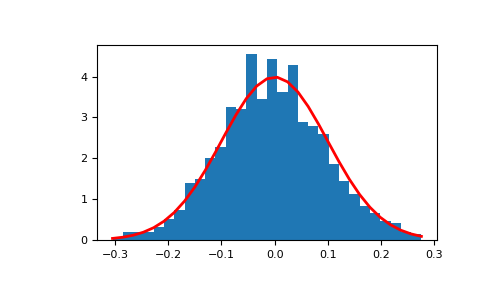

In [9]:
# Simulação de dados de 5 sensores durante 100 dias (2D)
# Cada linha é um dia, cada coluna é um sensor

# Gera 100x5 valores aleatórios da distribuição normal com média 20°C e desvio padrão de 5°C.
dados_sensores = np.random.normal(loc=20, scale=5, size=(100, 5))

# Array 2D: 100 dias × 5 sensores
print(np.array2string(dados_sensores, precision = 1, threshold=5))

#           sensor 0  sensor 1   sensor 2   sensor 3   sensor 4
# dia 1   [   20.1      21.7       18.1       28.9       27.2    ]
# dia 2   [   17.3      14.6       19.2       15.1       17.8    ]
# dia 3   [   21.7      19.5       22.3       18.3       27.6    ]
# ...     [    ...       ...        ...      ...          ...    ]
# dia 99  [   22.2      23.1       17.8       22.1       28.2    ]
# dia 100 [   21.8      23.9       15.2       28.4       29.5    ]

# ============================================================================
# ATRIBUTOS ESSENCIAIS DO ARRAY NUMPY PARA ANÁLISE INDUSTRIAL
# ============================================================================

# ndim: número de dimensões do array (também chamado de "rank" em álgebra linear)
print(f"\nDimensões da matriz criada: {dados_sensores.ndim}")

# shape: tupla com o tamanho de cada dimensão (linhas, colunas)
print(f"Formato (Dias x Sensores): {dados_sensores.shape}")

# dtype: tipo de dado armazenado no array
print(f"Tipo de dado: {dados_sensores.dtype}")
# float64 = ponto flutuante de 64 bits (padrão do numpy)
# Faixa aproximada: ±1.8 × 10³⁰⁸ | Precisão: ~15-17 dígitos significativos

[[23.3 20.8 29.  18.2 16.5]
 [16.3 14.3 19.5 13.7 15.8]
 [15.1 14.5 21.3 16.5 12.7]
 ...
 [22.1 15.6 11.2 24.2 19.2]
 [17.9 14.2 27.7 16.3 23.8]
 [23.7 11.4 12.1 26.5 22.6]]

Dimensões da matriz criada: 2
Formato (Dias x Sensores): (100, 5)
Tipo de dado: float64


### Indexação Básica

Para localizar qualquer dado específico dentro dessa matriz dados_sensores, o NumPy utiliza a sintaxe de coordenadas baseada em [linha, coluna], separada por uma vírgula.

Assim como na indexação simples, a contagem de linhas e colunas sempre começa no zero (0).

1. Localizando um único ponto (Escalar)
Se você quiser saber a temperatura exata coletada pelo Sensor 3 (coluna índice 3) no Dia 1 (linha índice 0):

In [10]:
print(f"Temperatura do Sensor 3 no dia 1: {dados_sensores[0, 3]:.1f} °C")

Temperatura do Sensor 3 no dia 1: 18.2 °C


Assim como listas em Python, podemos usar índices negativos (que contam a partir do final) ou positivos (a partir do início). Para 100 dias:

| Índice Negativo | Índice Positivo |
|:----------------|----------------:|
| `-1` (último elemento)            | `99`            |
| `-2`            | `98`            |
| `...`           | `...`           |
| `-99`           | `1`             |
| `-100`          | `0` (primeiro elemento)             |

**Regra:** O índice negativo `-k` acessa o mesmo elemento que `N - k` (onde `N` é o número de elementos naquela dimensão).

In [11]:
print(f"Temperatura do sensor 4 no último dia: {dados_sensores[-1, -1]:.1f} °C")

Temperatura do sensor 4 no último dia: 22.6 °C


### Slicing e o padrão ::

O fatiamento (```slicing```) permite extrair janelas específicas de tempo.

A sintaxe básica do fatiamento utiliza até três argumentos separados por dois-pontos dentro dos colchetes: [início:fim:passo].

* início: O índice onde o fatiamento começa (inclisivo), valor padrão: 0.

* fim: O índice onde o fatiamento termina (exclusivo, ou seja, o elemento nesta posição não entra no resultado), caso omitido recupera-se até o último índice.

* passo: O intervalo de elementos que você vai pular. Se for 1, pega todos os elementos seguidos. Se for 2, pega um e pula outro, etc.

Se você omitir os valores (deixando apenas [::] ou mesmo [:]), o Python adota os valores padrões: o início se torna o começo da sequência, o fim se torna o final dela, e o passo se torna 1.

In [12]:
# 1. SLICING: Selecionar os primeiros 5 dias (linhas) de todos os sensores (colunas)
janela_primeiros_5_dias = dados_sensores[0:5:1] # Podemos simplificar escrevendo apenas [:5]

print(f"{'Dia:':7}{'Sensor 0':12}{'Sensor 1':12}{'Sensor 2':12}{'Sensor 3':12}{'Sensor 4':12}")
for dia, medidas in enumerate(janela_primeiros_5_dias):
  print(f"{dia + 1:3} | {medidas}")

Dia:   Sensor 0    Sensor 1    Sensor 2    Sensor 3    Sensor 4    
  1 | [23.29238216 20.75922993 28.95903832 18.22663358 16.5225406 ]
  2 | [16.25099113 14.29774148 19.46992593 13.67713446 15.84629804]
  3 | [15.09017842 14.52138869 21.2910113  16.45688074 12.73699997]
  4 | [16.40777381 13.22653601 17.80910614 22.28317818 25.09948004]
  5 | [10.70448641 18.22209264 16.82227    22.29833557 21.8439914 ]


#### 💡 Pratique: Extraindo Leituras de um Sensor

Utilizando o dataset de sensores criado anteriormente, extraia apenas as leituras do Sensor 3 (coluna 3) para os últimos 20 dias do registro.

In [13]:
# --- SUA SOLUÇÃO AQUI ---
janela_ultimos_20_dias = dados_sensores[-20:, 3:4]

janela_ultimos_20_dias.shape

total_de_dias = janela_ultimos_20_dias.shape[0]
primeiro_dia = total_de_dias - 20 + 1

print(f"{'Dia':7}{'Sensor 3':12}")
for dia, medidas in enumerate(janela_ultimos_20_dias):
  print(f"{primeiro_dia + dia:3} | {medidas}")


Dia    Sensor 3    
  1 | [17.75586613]
  2 | [20.46799102]
  3 | [9.94863622]
  4 | [10.69692036]
  5 | [13.213293]
  6 | [22.26278573]
  7 | [20.14623816]
  8 | [19.93528287]
  9 | [17.44545265]
 10 | [24.24486677]
 11 | [28.97134711]
 12 | [16.11668024]
 13 | [18.31472357]
 14 | [17.61543402]
 15 | [18.96972452]
 16 | [12.47625491]
 17 | [27.22473454]
 18 | [24.16134244]
 19 | [16.30835797]
 20 | [26.51017972]


## Seção 4: Vetorização

Vetorização é o conceito central do NumPy e uma das razões pelas quais ele é tão rápido.
Em vez de processar os dados elemento por elemento usando loops for e condicionais if (estilo Python puro), a vetorização permite que você aplique operações em todo o array de uma única vez, aproveitando as funções otimizadas em C e Fortran por baixo dos panos.
Isso traz duas grandes vantagens:

Performance: ganhos de 10x a 100x em operações com grandes volumes de dados.
Código mais limpo e legível: menos linhas e menos chance de erro.

O NumPy consegue isso através de duas principais técnicas:

* Universal Functions (ufuncs) — funções que operam elemento a elemento de forma vetorizada (np.sqrt(), np.log(), np.exp(), +, -, >, <, etc.).

* Broadcasting — capacidade de operar arrays de tamanhos diferentes sem fazer cópias desnecessárias.

### 4.1 Universal Functions (ufunc)

As funções universais (ufuncs) são o coração da vetorização no NumPy.

Uma ufunc é uma função otimizada em C que opera elemento por elemento sobre arrays (ou escalares), aplicando a mesma operação em todos os dados de forma simultânea. Elas são projetadas para serem extremamente rápidas e substituem a necessidade de escrever loops for manuais em Python.

Para consultar todas as funções universais disponíveis: https://numpy.org/doc/stable/reference/ufuncs.html#available-ufuncs

In [14]:
# Matriz com 1000 dias x 1000 sensores
pressao = np.random.uniform(low=50, high=100, size=(1000, 1000))

# Exemplos de ufuncs
pressao_em_kpa = pressao * 6.89476 + 15     # multiplicação e soma
pressao_normalizada = (pressao - 75) / 25   # subtração e divisão

pressao_somada = np.sum(pressao)    # Soma de todas as pressões
pressao_media = np.mean(pressao)    # Média de todas as pressões
pressao_maxima = np.max(pressao)    # Máxima pressão
pressao_minima = np.min(pressao)    # Mínima pressão

raiz_quadrada = np.sqrt(pressao[pressao > 0])            # Raiz quadrada aplicada apenas a valores positivos
log_pressao = np.log(pressao[pressao > 0])               # função logarítmica  aplicada apenas a valores positivos
acima_do_limite = pressao > 80              # comparação (retorna máscara booleana)

#### ⚙️Axis (Eixos)

O parâmetro `axis` define **ao longo de qual dimensão** a operação será realizada.

Em uma matriz **(linhas × colunas)**:

- **`axis=0`** → **Vertical** (colapsa as linhas)  
  Resultado: **1 valor por coluna**  
  ```python
  media_por_sensor = pressao.mean(axis=0)   # shape: (1000,)
  ```
- **`axis=1`** → **Horizontal** (colapsa as colunas)  
  Resultado: **1 valor por linha**
  ```python
  media_por_dia = pressao.mean(axis=1)      # shape: (1000,)
  ```

In [15]:
# axis=0 → por coluna (por sensor)
media_por_sensor = pressao.mean(axis=0)
print(f"Média por sensor (axis=0) → shape: {media_por_sensor.shape}")
print(f"Primeiros 5 sensores: {media_por_sensor[:5].round(3)}\n")

# axis=1 → por linha (por dia)
media_por_dia = pressao.mean(axis=1)
print(f"Média por dia (axis=1)   → shape: {media_por_dia.shape}")
print(f"Primeiros 5 dias:      {media_por_dia[:5].round(3)}")

Média por sensor (axis=0) → shape: (1000,)
Primeiros 5 sensores: [75.127 75.201 74.511 74.727 75.112]

Média por dia (axis=1)   → shape: (1000,)
Primeiros 5 dias:      [74.678 74.855 75.551 75.865 74.455]


#### ❗ Squeezing

Quando você executa `pressao.mean(axis=0)` ou `pressao.mean(axis=1)`, o resultado tem `shape (1000,)` nas duas situações.

Isso acontece porque o NumPy **automaticamente remove dimensões de tamanho 1** após uma agregação. Esse comportamento é chamado de **Squeezing** (do inglês *squeeze* = apertar/encolher).

##### Por que o NumPy faz isso?

Na prática, você quase sempre quer um **vetor simples** com os resultados para:
- Plotar gráficos
- Fazer novas operações vetorizadas
- Indexar facilmente (`media[0]`)

Manter dimensões extras como `(1, 1000)` ou `(1000, 1)` seria inconveniente na maioria dos casos.

##### Quando você precisa manter a dimensão?

Use o parâmetro `keepdims=True`:

```python
media_por_sensor = pressao.mean(axis=0, keepdims=True)  # shape (1, 1000)
media_por_dia    = pressao.mean(axis=1, keepdims=True)  # shape (1000, 1)
```




#### 💡 Pratique: Análise de Temperaturas em uma Planta Solar

Uma planta de energia solar monitora a temperatura de 30 dias em 20 sensores distribuídos pela instalação. Para simular os dados, utilize a matriz abaixo:

```python
temperaturas = np.random.uniform(low=15, high=45, size=(30, 20))
```

Utilizando apenas operações vetorizadas e funções universais do NumPy, responda:

1. Qual é a temperatura média de toda a planta?
2. Qual foi a maior temperatura registrada?
3. Qual foi a menor temperatura registrada?
4. Calcule a temperatura média de cada sensor.
5. Calcule a temperatura média de cada dia.
6. Conte quantas medições ficaram acima de 35°C.

In [16]:
# Sua solução aqui.
temperaturas = np.random.uniform(low=15, high=45, size=(30, 20))


In [17]:
# Primeira questão
temperatura_media = np.mean(temperaturas)
print(f"temperatura_media: {temperatura_media}")

temperatura_media: 29.871530839940647


In [18]:
# Segunda questão

maior_temperatura = np.max(temperaturas)
print(f"Maior temperatura: {maior_temperatura}")

Maior temperatura: 44.968918252594094


In [19]:
# terceira questão

menor_temperatura = np.min(temperaturas)
print(f"Menor temperatura: {menor_temperatura}")

Menor temperatura: 15.002049286903029


In [20]:
# Quarta questão

temp_media_por_sensor = temperaturas.mean(axis=0)
print(f"Temperatura media por sensor: {temp_media_por_sensor}")

Temperatura media por sensor: [27.339672   29.44824065 29.44041531 30.52254498 26.97056855 28.32066777
 30.21257003 28.19666154 32.22988236 30.89283367 31.42472611 30.49267601
 32.25485296 27.4998589  30.86441308 30.75462359 29.0007556  29.36553799
 31.56892772 30.63018798]


In [21]:
# Quinta questão

temp_media_de_cada_dia = temperaturas.mean(axis=1)
print(f"Temperatura média de cada dia: {temp_media_de_cada_dia}")

Temperatura média de cada dia: [26.95462269 27.01474244 29.4703236  32.12455447 31.10201365 30.7530712
 28.57296596 30.43335514 32.09745639 27.38184117 30.200652   29.78474004
 29.46429468 32.28323426 27.89240789 32.00919824 30.98602317 34.08829099
 30.32341062 29.79597225 29.67557005 29.83367184 28.45253363 26.78569534
 30.47991791 27.76605603 29.64570562 28.53711279 31.34393687 30.89255427]


In [22]:
# Sexta questão

temperaturas_acima_de_35 = np.sum(temperaturas > 35)
print(f"Numero de temperaturas acima de 45 graus: {temperaturas_acima_de_35}")

Numero de temperaturas acima de 45 graus: 189


### 4.2 Broadcasting

O Broadcasting permite realizar operações matemáticas entre arrays de tamanhos diferentes, sem a necessidade de duplicar dados manualmente. O NumPy entende a repetição dos dados implicitamente.

#### Regras do Broadcasting:

Duas dimensões são compatíveis se:
- São **iguais**, ou
- Uma delas é **1** (esta será repetida para ficar compatível com a dimensão necessária para realizar a operação)

#### Exemplos:

**Exemplo 1: Escalar + Array 2D**
```
Array original (2, 3):        Escalar:              Resultado (2, 3):
┌─────────────┐               ┌─────┐               ┌─────────────┐
│ 1   2   3   │               │ 10  │               │ 11  12  13  │
│ 4   5   6   │     +         └─────┘         =     │ 14  15  16  │
└─────────────┘                                     └─────────────┘

Broadcasting: O escalar 10 é "esticado" para:
┌─────────────┐
│ 10  10  10  │
│ 10  10  10  │
└─────────────┘
```

**Exemplo 2: Array 2D + Array Coluna**
```
Array (2, 3):              Coluna (2, 1):           Resultado (2, 3):
┌─────────────┐            ┌────┐                  ┌─────────────┐
│ 1   2   3   │            │ 10 │                  │ 11  12  13  │
│ 4   5   6   │     +      │ 20 │            =     │ 24  25  26  │
└─────────────┘            └────┘                  └─────────────┘

Broadcasting: A coluna se repete para as 3 colunas do array:
┌─────────────┐
│ 10  10  10  │  ← mesma coluna repetida
│ 20  20  20  │  ← mesma coluna repetida
└─────────────┘
```



In [23]:
print("Shape original:", pressao.shape)

# === Normalização Z-Score usando Broadcasting ===

# Calcula média e desvio padrão por sensor (ao longo dos dias)
media_por_sensor = pressao.mean(axis=0, keepdims=True)   # shape (1, 1000)
std_por_sensor   = pressao.std(axis=0, keepdims=True)    # shape (1, 1000)

# Normalização com Broadcasting
pressao_normalizada = (pressao - media_por_sensor) / std_por_sensor

print("Shape após normalização:", pressao_normalizada.shape)
print(f"Média aproximada por sensor: {pressao_normalizada.mean(axis=0).mean():.4f}")
print(f"Desvio padrão aproximado por sensor: {pressao_normalizada.std(axis=0).mean():.4f}")

Shape original: (1000, 1000)
Shape após normalização: (1000, 1000)
Média aproximada por sensor: 0.0000
Desvio padrão aproximado por sensor: 1.0000


Exemplo prático:

Imagine que você tem um array de 1000 sensores × 1000 medições e quer normalizar por subtrair o valor médio de cada sensor. Com Broadcasting, você pode fazer isso facilmente:

In [24]:
pressao = np.random.normal(loc=75, scale=25, size=(1000, 1000))

media_por_sensor = pressao.mean(axis=1, keepdims=True)  # shape (1000, 1)
pressao_normalizada = pressao - media_por_sensor        # Broadcasting acontece aqui

In [25]:
# Média de temperatura ao longo dos 100 dias para CADA sensor
media_por_sensor = dados_sensores.mean(axis=0)

# Identificar o dia com a maior variabilidade entre os sensores
variabilidade_diaria = dados_sensores.std(axis=1)
dia_instavel = variabilidade_diaria.argmax()

# Normalização por sensor (Broadcasting): Subtrair a média de cada coluna
dados_calibrados = dados_sensores - media_por_sensor

# Operações com Axis:

# Operação                    axis    Direção      Resultado                    Significado
# np.mean(arr, axis=0)        0       ↓ vertical   [26.5, 31.5, 29.5]          Média por sensor
# np.std(arr, axis=1)         1       → horizontal [2.16, 2.16, 2.16, 2.16]    Variabilidade diária
# np.sum(arr, axis=0)         0       ↓ vertical   [106, 126, 118]             Total por sensor
# np.sum(arr, axis=1)         1       → horizontal [83, 88, 87, 92]            Total por dia

# Regra:

# axis=0 (colpsa as linhas em uma) → Achatamento VERTICAL → Resultado tem tamanho = número de COLUNAS
# axis=1 (colpsa as colunas em uma) → Achatamento HORIZONTAL → Resultado tem tamanho = número de LINHAS

#### 💡 Pratique: Calibração de Sensores em uma Siderúrgica

Uma siderúrgica possui 50 fornos industriais, cada um monitorado por um sensor de temperatura. Durante 365 dias, foi registrada a temperatura média diária de cada forno.

Na matriz abaixo, cada linha representa um dia e cada coluna representa um forno:

```python
temperaturas = np.random.normal(loc=1200, scale=50, size=(365, 50))
```

Após uma inspeção, foi identificado que cada sensor possui um erro de calibração (offset) diferente:

```python
offsets = np.random.uniform(low=-10, high=10, size=(50,))
```

Utilizando Broadcasting, responda:

1. Corrija as leituras dos sensores subtraindo o respectivo offset de cada coluna.

2. Calcule a temperatura média de cada forno após a calibração.

3. Normalize os dados utilizando Z-Score por sensor, empregando Broadcasting.

In [26]:
# Leitura dos sensores corrigidas

temperaturas = np.random.normal(loc=1200, scale=50, size=(365, 50))
offsets = np.random.uniform(low=-10, high=10, size=(50,))

leituras_corrigidas = temperaturas - offsets

leituras_corrigidas.shape



(365, 50)

In [34]:
# Temperatura média de cada forno após a calibração

temp_media_de_cada_forno = leituras_corrigidas.mean(axis=0)
print(f"{temp_media_de_cada_forno.shape[0]}")
print(f"Temperatura média de cada forno\n {temp_media_de_cada_forno}")

50
Temperatura média de cada forno
 [1200.0978385  1206.71410725 1209.1104453  1210.88712541 1203.44298109
 1203.82840037 1198.78748846 1204.15711417 1202.01401408 1214.99595501
 1200.2031414  1211.61718204 1203.07741801 1205.58008979 1208.78292619
 1192.88365996 1202.4539458  1190.6026431  1208.88843017 1201.23246218
 1212.33149374 1202.43241608 1211.45029912 1198.82320203 1200.95823594
 1200.48882496 1194.75107298 1192.34044351 1192.53240977 1194.51194589
 1194.12642114 1203.25753908 1196.73697398 1206.96502328 1191.81955559
 1198.00044149 1208.60253034 1191.3217267  1192.6337717  1208.31590789
 1204.31531155 1195.26871972 1192.75434785 1197.66454373 1194.15809616
 1206.58454982 1196.10096728 1200.56072845 1202.61345902 1206.30342444]


In [36]:
# (temperaturas - temp_media_de_cada_sensor)/ std_por_sensores

std_por_forno = leituras_corrigidas.std(axis=0)

temps_normalizadas = (temperaturas - temp_media_de_cada_forno)/ std_por_forno

print(f"Temperaturas normalizadas: \n {temps_normalizadas}")
print(f"Formato do meu dataset: {temps_normalizadas.shape}")

Temperaturas normalizadas: 
 [[-0.21337623  0.30948096 -0.07576142 ...  0.66962196 -0.96797024
  -0.22276975]
 [ 0.43550834 -1.04436956 -1.87504693 ...  0.42860614 -0.7529186
   0.1621861 ]
 [-0.4691794  -0.21776211 -0.4949109  ...  1.18514928 -0.32698774
  -0.97125117]
 ...
 [-0.18019316 -0.18978702 -1.03489437 ...  0.54273769  2.23918964
   2.09122277]
 [-0.18274914 -0.33299253 -0.75700208 ... -1.81101884  0.37183657
   0.52567956]
 [-0.23377832  0.73158984  0.88539805 ... -0.90098083  0.87007166
  -0.10233121]]
Formato do meu dataset: (365, 50)


#### ⚙️ Indexação Booleana

O ```Boolean Indexing``` (Indexação Booleana) é uma técnica de filtragem rápida que usa condições lógicas (>, <, ==, !=) para selecionar dados dentro de um array, substituindo totalmente a necessidade de usar loops for e condicionais if.

Em vez de buscar um dado pela sua posição numérica (como "linha 2, coluna 3"), você faz uma pergunta para o NumPy. Ele te responde criando uma Máscara Booleana — uma grade com o mesmo tamanho dos seus dados, mas preenchida apenas com True (onde a condição é verdadeira) e False (onde é falsa).

Quando você passa essa máscara de True e False dentro dos colchetes do array original, o NumPy faz uma varredura ultraveloz e extrai apenas os números que estavam sobrepostos ao valor True.

In [27]:
# BOOLEAN INDEXING: Filtrar temperaturas acima de 30°C
anomalias_mask = janela_primeiros_5_dias > 25
valores_criticos = janela_primeiros_5_dias[anomalias_mask]

# --- VISUALIZAÇÃO ---
print(f"{'Dia':5} | {'Sensor':6} | {'Temperatura'} ")
print("-" * 32)

# np.ndindex gera os índices de linha (dia) e coluna (sensor) automaticamente:
# (0,0), (0,1), (0,2), ...
for dia, sensor in np.ndindex(janela_primeiros_5_dias.shape):
    temp = janela_primeiros_5_dias[dia, sensor]
    print(f"{dia+1:5} | {sensor+1:6} | {temp:7.2f} °C ")


Dia   | Sensor | Temperatura 
--------------------------------
    1 |      1 |   23.29 °C 
    1 |      2 |   20.76 °C 
    1 |      3 |   28.96 °C 
    1 |      4 |   18.23 °C 
    1 |      5 |   16.52 °C 
    2 |      1 |   16.25 °C 
    2 |      2 |   14.30 °C 
    2 |      3 |   19.47 °C 
    2 |      4 |   13.68 °C 
    2 |      5 |   15.85 °C 
    3 |      1 |   15.09 °C 
    3 |      2 |   14.52 °C 
    3 |      3 |   21.29 °C 
    3 |      4 |   16.46 °C 
    3 |      5 |   12.74 °C 
    4 |      1 |   16.41 °C 
    4 |      2 |   13.23 °C 
    4 |      3 |   17.81 °C 
    4 |      4 |   22.28 °C 
    4 |      5 |   25.10 °C 
    5 |      1 |   10.70 °C 
    5 |      2 |   18.22 °C 
    5 |      3 |   16.82 °C 
    5 |      4 |   22.30 °C 
    5 |      5 |   21.84 °C 


❗Você pode usar expressões lógicas para indexar os elementos em um array.

```
& equivale ao AND
| equivale ao OR
~ equivale ao NOT
```


In [28]:
# Selecionando os temperaturas no intervalo [17°C, 21°C].
janela_primeiros_5_dias[(17 <= janela_primeiros_5_dias) & (janela_primeiros_5_dias <= 21)]

array([20.75922993, 18.22663358, 19.46992593, 17.80910614, 18.22209264])

Diferente do comando de célula que usamos antes, aqui utilizamos a magic function %timeit (com apenas um sinal de %) para cronometrar apenas a linha específica onde ela foi inserida.

Execute a célula abaixo e compare o abismo de desempenho entre o loop nativo do Python e a velocidade de processamento do NumPy:

In [29]:
# 1. Preparação dos dados (1 milhão de leituras de pressão em PSI)
pressao_limite = 80.0

# 1000 x 1000 = 1 milhão de elementos
# Média 75 psi, desvio padrão 25 psi
pressao_array = np.random.normal(loc=75, scale=25, size=(1000, 1000))
pressao_lista = pressao_array.tolist()

print("--- DESEMPENHO EM FILTRAGEM DE DADOS (1 MILHÃO DE REGISTROS) ---\n")

# 2. Python Puro (List Comprehension)
print("Tempo com Python Puro (List Comprehension + IF):")
%timeit -r 5 -n 50 [p for sublista in pressao_lista for p in sublista if p > pressao_limite]

# 3. NumPy (Vetorizado)
print("\nTempo com NumPy (Boolean Indexing):")
%timeit -r 5 -n 50 pressao_array[pressao_array > pressao_limite]

--- DESEMPENHO EM FILTRAGEM DE DADOS (1 MILHÃO DE REGISTROS) ---

Tempo com Python Puro (List Comprehension + IF):
65.4 ms ± 15.9 ms per loop (mean ± std. dev. of 5 runs, 50 loops each)

Tempo com NumPy (Boolean Indexing):
8.47 ms ± 295 µs per loop (mean ± std. dev. of 5 runs, 50 loops each)


#### ⚙️ np.where -  Operação ternária vetorizada

O `np.where` é uma função do NumPy que pode ser usada para processar valores em uma matriz. Ela permite criar um novo array escolhendo valores diferentes para cada posição com base em uma condição.

#### Sintaxes:

```python
np.where(condição, valor_se_verdadeiro, valor_se_falso)
```

No exemplo abaixo cria-se uma matriz de status para cada medição presente na matriz ```janela_primeiros_5_dias```.

In [30]:
# Criação da matriz de status dos sensores
status_sensores = np.where(janela_primeiros_5_dias > 25, 'Crítico', 'Normal')

# --- VISUALIZAÇÃO ---
print(f"{'Dia':5} | {'Sensor':6} | {'Temperatura':8} | {'Status'} ")
print("-" * 42)

# np.ndindex gera os índices de linha (dia) e coluna (sensor) automaticamente:
# (0,0), (0,1), (0,2), ...
for dia, sensor in np.ndindex(janela_primeiros_5_dias.shape):
    temp = janela_primeiros_5_dias[dia, sensor]
    status = status_sensores[dia, sensor]
    print(f"{dia+1:5} | {sensor+1:6} | {temp:7.2f} °C  | {status}")

Dia   | Sensor | Temperatura | Status 
------------------------------------------
    1 |      1 |   23.29 °C  | Normal
    1 |      2 |   20.76 °C  | Normal
    1 |      3 |   28.96 °C  | Crítico
    1 |      4 |   18.23 °C  | Normal
    1 |      5 |   16.52 °C  | Normal
    2 |      1 |   16.25 °C  | Normal
    2 |      2 |   14.30 °C  | Normal
    2 |      3 |   19.47 °C  | Normal
    2 |      4 |   13.68 °C  | Normal
    2 |      5 |   15.85 °C  | Normal
    3 |      1 |   15.09 °C  | Normal
    3 |      2 |   14.52 °C  | Normal
    3 |      3 |   21.29 °C  | Normal
    3 |      4 |   16.46 °C  | Normal
    3 |      5 |   12.74 °C  | Normal
    4 |      1 |   16.41 °C  | Normal
    4 |      2 |   13.23 °C  | Normal
    4 |      3 |   17.81 °C  | Normal
    4 |      4 |   22.28 °C  | Normal
    4 |      5 |   25.10 °C  | Crítico
    5 |      1 |   10.70 °C  | Normal
    5 |      2 |   18.22 °C  | Normal
    5 |      3 |   16.82 °C  | Normal
    5 |      4 |   22.30 °C  | Normal
    

#### 💡 Pratique: Monitoramento de Pressão e Detecção de Alertas

No controle de qualidade de uma linha de produção, pressões abaixo de 60.0 PSI indicam subpressão (risco de parada da máquina), e pressões acima de 90.0 PSI indicam sobrecarga (risco de explosão).

Utilizando o array pressao_array (com as 1 milhão de leituras de pressão criadas na célula anterior), resolva as duas etapas abaixo utilizando-se dos conceitos visto nesta seção:

* **Etapa A (Boolean Indexing):** Crie uma máscara booleana para filtrar e isolar em uma nova variável apenas os valores que estão em situação de sobrecarga (acima de 90.0 PSI). Descubra quantas leituras críticas foram registradas utilizando o atributo .size.

* **Etapa B (np.where):** Crie um novo array chamado status_pressao que rotule automaticamente cada uma das 1 milhão de leituras: se a pressão for maior que 90.0, o rótulo deve ser 'ALERTA'; caso contrário, deve ser 'ESTÁVEL'.

In [43]:
# --- SUA SOLUÇÃO AQUI ---

# Etapa A: Filtragem com Máscara Booleana

# Situação de sobrecarga pressao > 90
# verificar quantas foram registradas com esse status com o .size

pressoes_situacao_sobrecarga = pressao_array[pressao_array > 90]
registros = pressoes_situacao_sobrecarga.size
registros

# Etapa B: Rotulação Condicional com np.where

status_pressao = np.where(pressao_array > 90, "Alerta", "Estável")


# Trazendo a vizualização

for dia, sensor in np.ndindex(pressao_array.shape):
    pressao = pressao_array[dia,sensor]
    status = status_pressao[dia,sensor]
    print(f"{dia+1:5} | {sensor+1:5} | {pressao:5} | {status:10}")


print(f"formato do array status_pressao {status_pressao}")

Streaming output truncated to the last 5000 lines.
  996 |     8 | 84.51689655939715 | Estável   
  996 |     9 | 42.32600561939811 | Estável   
  996 |    10 | 73.27213248111819 | Estável   
  996 |    11 | 98.7979229311254 | Alerta    
  996 |    12 | 67.76519658890815 | Estável   
  996 |    13 | 105.17425330199359 | Alerta    
  996 |    14 | 53.575429432933674 | Estável   
  996 |    15 | 105.56465572161504 | Alerta    
  996 |    16 | 77.13247092220045 | Estável   
  996 |    17 | 82.19506345353066 | Estável   
  996 |    18 | 48.87838610040072 | Estável   
  996 |    19 | 115.34692801752527 | Alerta    
  996 |    20 | 80.05056106952404 | Estável   
  996 |    21 | 44.22765574924262 | Estável   
  996 |    22 | 116.38505177432668 | Alerta    
  996 |    23 | 102.73332581880246 | Alerta    
  996 |    24 | 98.90617715730184 | Alerta    
  996 |    25 | 52.80583596243936 | Estável   
  996 |    26 | 123.42839506207795 | Alerta    
  996 |    27 | 76.68868679063348 | Estável   
  9